# FIFA World Cup 2022 Data Analysis

**Checkpoint 2**

This notebook uses StatsBomb's open event data for the 2022 FIFA World Cup.

**Data source:** [Hudl / StatsBomb Open Data](https://github.com/hudl/open-data). 

## 1. Import packages

`statsbombpy` retrieves match and event data from StatsBomb's open-data collection. `pandas` organizes and parses the data, `scipy` performs the hypothesis test, and `matplotlib` creates the plot.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsbombpy import sb
import warnings
from statsbombpy.api_client import NoAuthWarning

warnings.filterwarnings("ignore", category=NoAuthWarning)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

## 2. Importing and organizing the 2022 World Cup data

StatsBomb identifies FIFA World Cup competition ID `43` and the 2022 season as season ID `106`.

In [20]:
competition_id = 43
season_id = 106

matches = sb.matches(competition_id=competition_id, season_id=season_id)
matches = matches.copy()

print(f"Matches loaded: {len(matches)}")
display(matches.head())
print("Match-list columns:", matches.columns.tolist())

Matches loaded: 64


,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,competition_id,competition_country_name,competition_name,competition,season_id,...,home_manager_id,home_manager_name,home_manager_nickname,home_manager_dob,home_manager_country_id,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
0,3857276,2022-12-01,15:00:00.000,1,2,available,available,2026-05-04T01:46:04.664252,2026-05-04T01:50:33.318123,3,43,International,FIFA World Cup,International - FIFA World Cup,106,...,4435,John Herdman,NaN,1975-07-19,68,England,1000518,Walid Regragui,NaN,1975-09-23,154,Morocco,1.1.0,2,2
1,3857271,2022-11-21,13:00:00.000,6,2,available,available,2026-05-04T01:40:47.671394,2026-05-04T01:43:30.216315,1,43,International,FIFA World Cup,International - FIFA World Cup,106,...,277,Gareth Southgate,NaN,1970-09-03,68,England,645,Carlos Manuel Brito Leal Queiróz,Carlos Queiroz,1953-03-01,183,Portugal,1.1.0,2,2
2,3857296,2022-12-01,15:00:00.000,0,0,available,available,2026-05-04T01:44:02.255386,2026-05-04T01:50:06.343225,3,43,International,FIFA World Cup,International - FIFA World Cup,106,...,307,Zlatko Dalić,NaN,1966-10-26,56,Croatia,263,Roberto Martínez Montoliú,Roberto Martínez,1973-07-13,214,Spain,1.1.0,2,2
3,3857274,2022-11-25,16:00:00.000,1,1,available,available,2026-05-04T01:43:00.444702,2026-05-04T01:50:07.646458,2,43,International,FIFA World Cup,International - FIFA World Cup,106,...,788,Louis van Gaal,NaN,1951-08-08,160,Netherlands,2881,Gustavo Julio Alfaro,Gustavo Alfaro,1962-08-14,11,Argentina,1.1.0,2,2
4,3857255,2022-12-01,19:00:00.000,2,1,available,available,2026-05-04T01:42:55.630428,2026-05-04T01:49:36.594944,3,43,International,FIFA World Cup,International - FIFA World Cup,106,...,5699,Hajime Moriyasu,NaN,1968-08-23,114,Japan,793,Luis Enrique Martínez García,Luis Enrique,1970-05-08,214,Spain,1.1.0,2,2


Match-list columns: ['match_id', 'match_date', 'kick_off', 'home_score', 'away_score', 'match_status', 'match_status_360', 'last_updated', 'last_updated_360', 'match_week', 'competition_id', 'competition_country_name', 'competition_name', 'competition', 'season_id', 'season', 'home_team_id', 'home_team', 'home_team_gender', 'home_team_group', 'home_team_country_id', 'home_team_country_name', 'away_team_id', 'away_team', 'away_team_gender', 'away_team_group', 'away_team_country_id', 'away_team_country_name', 'competition_stage_id', 'competition_stage', 'stadium_id', 'stadium', 'stadium_country_id', 'stadium_country_name', 'referee_id', 'referee', 'referee_country_id', 'referee_country_name', 'home_managers', 'away_managers', 'home_manager_id', 'home_manager_name', 'home_manager_nickname', 'home_manager_dob', 'home_manager_country_id', 'home_manager_country_name', 'away_manager_id', 'away_manager_name', 'away_manager_nickname', 'away_manager_dob', 'away_manager_country_id', 'away_manager

In [21]:
# Retrieve events match by match and retain shot events in regulation halves.
shot_frames = []

for match_id in matches["match_id"]:
    events = sb.events(match_id=match_id)
    if events is None or events.empty:
        continue

    # Standardize the key fields before combining data from different matches.
    required = {"type", "period", "team", "minute"}
    if not required.issubset(events.columns):
        missing = required - set(events.columns)
        raise ValueError(f"Expected event columns missing for match {match_id}: {missing}")

    shots = events.loc[
        (events["type"] == "Shot") & (events["period"].isin([1, 2]))
    ].copy()

    shots["match_id"] = match_id
    shots["minute"] = pd.to_numeric(shots["minute"], errors="coerce")
    shot_frames.append(shots)

if not shot_frames:
    raise ValueError("No regulation-time shots were returned. Check the competition/season IDs or data connection.")

shots_df = pd.concat(shot_frames, ignore_index=True)

# Convert the period to a readable category and normalize minute values.
shots_df["half"] = shots_df["period"].map({1: "First half", 2: "Second half"})
shots_df["period"] = pd.to_numeric(shots_df["period"], errors="coerce").astype("Int64")

print(f"Regulation-time shots loaded: {len(shots_df):,}")
print(f"Matches represented in shot data: {shots_df['match_id'].nunique()}")
display(shots_df[["match_id", "minute", "period", "half", "team"]].head())

Regulation-time shots loaded: 1,408
Matches represented in shot data: 64


,match_id,minute,period,half,team
0,3857276,2,1,First half,Canada
1,3857276,3,1,First half,Morocco
2,3857276,8,1,First half,Morocco
3,3857276,9,1,First half,Morocco
4,3857276,14,1,First half,Canada


## 3. Data analysis table

In [22]:
shot_counts = (
    shots_df.groupby(["match_id", "period"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[1, 2], fill_value=0)
    .rename(columns={1: "first_half_shots", 2: "second_half_shots"})
    .reset_index()
)

# Include every match in the match list, including a match with zero recorded shots in a half.
match_analysis = matches[["match_id", "home_team", "away_team"]].merge(
    shot_counts, on="match_id", how="left"
)
match_analysis[["first_half_shots", "second_half_shots"]] = (
    match_analysis[["first_half_shots", "second_half_shots"]].fillna(0).astype(int)
)
match_analysis["difference_second_minus_first"] = (
    match_analysis["second_half_shots"] - match_analysis["first_half_shots"]
)

print("Match-level dataset shape:", match_analysis.shape)
print("Number of rows:", len(match_analysis))
print("Number of columns:", len(match_analysis.columns))
display(match_analysis.head())

Match-level dataset shape: (64, 6)
Number of rows: 64
Number of columns: 6


,match_id,home_team,away_team,first_half_shots,second_half_shots,difference_second_minus_first
0,3857276,Canada,Morocco,9,3,-6
1,3857271,England,Iran,8,13,5
2,3857296,Croatia,Belgium,11,16,5
3,3857274,Netherlands,Ecuador,8,9,1
4,3857255,Japan,Spain,7,11,4


## 4. Descriptive statistics

In [23]:
summary = match_analysis[["first_half_shots", "second_half_shots"]].agg(
    ["count", "mean", "std", "median", "min", "max"]
).T
summary = summary.rename_axis("half").reset_index()
display(summary.round(2))

print("Average difference (second half − first half):",
      round(match_analysis["difference_second_minus_first"].mean(), 2), "shots per match")

,half,count,mean,std,median,min,max
0,first_half_shots,64.0,9.48,3.63,9.0,3.0,18.0
1,second_half_shots,64.0,12.52,4.66,12.0,3.0,25.0


Average difference (second half − first half): 3.03 shots per match


## 5. Hypothesis test and plot

**Question:** Across 2022 World Cup matches, did the number of shots differ between the first and second halves of regulation time?

- **Null hypothesis (H₀):** The average within-match difference in shot counts (second half minus first half) is zero.
- **Alternative hypothesis (H₁):** The average within-match difference is not zero.
- **Method:** Paired t-test, comparing the two halves within each match.
- **Significance level:** 0.05.

The paired t-test is appropriate because both counts come from the same match.

In [24]:
first = match_analysis["first_half_shots"]
second = match_analysis["second_half_shots"]
differences = second - first

test_result = stats.ttest_rel(second, first, nan_policy="omit")
n = differences.notna().sum()
mean_diff = differences.mean()
sd_diff = differences.std(ddof=1)
se_diff = sd_diff / np.sqrt(n) if n > 0 else np.nan
critical_t = stats.t.ppf(0.975, df=n - 1) if n > 1 else np.nan
ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

print(f"Paired t-test: t = {test_result.statistic:.3f}, p = {test_result.pvalue:.4f}")
print(f"Mean difference (second − first half): {mean_diff:.2f} shots per match")
print(f"95% confidence interval for the mean difference: [{ci_low:.2f}, {ci_high:.2f}]")
print("Decision at alpha = 0.05:",
      "Reject H0" if test_result.pvalue < 0.05 else "Fail to reject H0")

Paired t-test: t = 4.529, p = 0.0000
Mean difference (second − first half): 3.03 shots per match
95% confidence interval for the mean difference: [1.69, 4.37]
Decision at alpha = 0.05: Reject H0


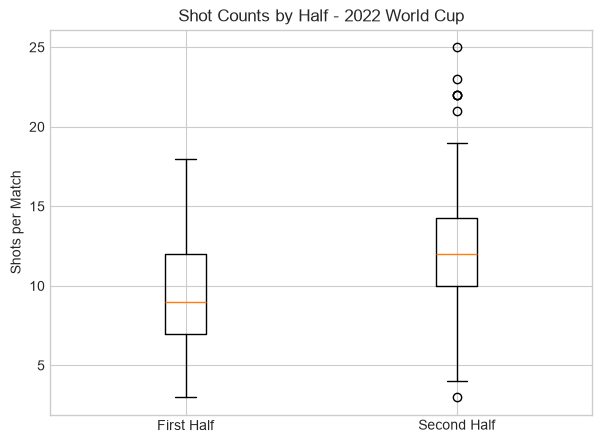

In [28]:
plt.figure(figsize=(7, 5))

plt.boxplot([first, second], tick_labels=["First Half", "Second Half"])

plt.ylabel("Shots per Match")
plt.title("Shot Counts by Half - 2022 World Cup")

plt.show()

## 6. Conclusion

In [26]:
alpha = 0.05
if test_result.pvalue < alpha:
    direction = "higher" if mean_diff > 0 else "lower"
    conclusion = (
        f"In the 2022 FIFA World Cup, teams recorded statistically different numbers of shots "
        f"between the first and second halves of regulation time (paired t-test: "
        f"t = {test_result.statistic:.2f}, p = {test_result.pvalue:.4f}). "
        f"On average, the second half had {abs(mean_diff):.2f} {direction} shots per match "
        f"than the first half (95% CI for second-half minus first-half difference: "
        f"{ci_low:.2f} to {ci_high:.2f})."
    )
else:
    conclusion = (
        f"In the 2022 FIFA World Cup, this analysis did not find statistically significant "
        f"evidence of a difference in shot counts between the first and second halves of "
        f"regulation time (paired t-test: t = {test_result.statistic:.2f}, "
        f"p = {test_result.pvalue:.4f}). The observed average difference was "
        f"{mean_diff:.2f} shots per match (95% CI: {ci_low:.2f} to {ci_high:.2f}). "
        f"This does not prove the halves are identical; it means the sample did not provide "
        f"sufficient evidence of a difference at the 0.05 significance level."
    )

print(conclusion)

In the 2022 FIFA World Cup, teams recorded statistically different numbers of shots between the first and second halves of regulation time (paired t-test: t = 4.53, p = 0.0000). On average, the second half had 3.03 higher shots per match than the first half (95% CI for second-half minus first-half difference: 1.69 to 4.37).
